# Empirical PC1--PC2 density per chain

For each $(d, \lambda, \text{chain})$ we project the $n = 1000$ samples in
$\mathbb{R}^d$ onto the top two principal components and plot the **empirical
2D density** of the projection (Gaussian KDE, Scott bandwidth). The
smallest-$\lambda$ row in each figure is the near-independent Gaussian
baseline against which higher-$\lambda$ structure is read.

Companion to `02_perchain_d1_d10.ipynb` (Figs 9, 11) and
`03_perchain_d100.ipynb` (Fig 12) — same $\lambda$ values, same per-$\lambda$
seeds, so the PC1--PC2 projections shown here are taken from the same chain
realisations as the scatter views in those notebooks.

Figures saved to `figs/`:

- `figs/pca_density_d10.pdf` (Figure 10)
- `figs/pca_density_d100.pdf` (Figure 13)

Approximate runtime: 5--10 minutes on a single CPU core (heaviest step is the
$d = 100$ chain simulation).

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from chain import r_c_of_d, simulate_Z_chain

FIGS = Path("figs")
FIGS.mkdir(exist_ok=True)

N = 1000
N_CHAINS = 5
GRID_RES = 120
PAD = 0.10
CMAP = "viridis"


def pca2(X):
    Xc = X - X.mean(axis=0, keepdims=True)
    if np.std(Xc) < 1e-12:
        Xc = Xc + 1e-12 * np.random.default_rng(0).standard_normal(size=Xc.shape)
    U, s, Vt = np.linalg.svd(Xc, full_matrices=False)
    scores = U[:, :2] * s[:2]
    for k in range(2):
        idx = int(np.argmax(np.abs(Vt[k])))
        if Vt[k, idx] < 0:
            scores[:, k] = -scores[:, k]
    return scores


def simulate_per_chain(d, n, lams, depth, n_chains, seeds, jitter=1e-8):
    out = np.empty((len(lams), n_chains, n, d))
    rc = r_c_of_d(d)
    for li, lam in enumerate(lams):
        r = lam * rc
        rng = np.random.default_rng(seeds[lam])
        for c in range(n_chains):
            snaps = simulate_Z_chain(r=r, n=n, d=d, n_steps=depth, rng=rng,
                                     save_depths=(depth,), jitter=jitter)
            out[li, c] = snaps[depth]
    return out


def empirical_kde_grid(scores, grid_res=GRID_RES, pad=PAD):
    s = scores
    xy_min = s.min(axis=0)
    xy_max = s.max(axis=0)
    span = xy_max - xy_min
    span = np.where(span < 1e-12, 1.0, span)
    lo = xy_min - pad * span
    hi = xy_max + pad * span
    lim = max(np.max(np.abs(lo)), np.max(np.abs(hi)))
    xs = np.linspace(-lim, lim, grid_res)
    ys = np.linspace(-lim, lim, grid_res)
    X, Y = np.meshgrid(xs, ys)
    pts = np.stack([X.ravel(), Y.ravel()], axis=0)
    try:
        kde = gaussian_kde(s.T)
        Z = kde(pts).reshape(X.shape)
    except np.linalg.LinAlgError:
        rng = np.random.default_rng(0)
        kde = gaussian_kde((s + 1e-9 * rng.standard_normal(s.shape)).T)
        Z = kde(pts).reshape(X.shape)
    return X, Y, Z, lim


def grid_density(snap, lams, d, depth, out_path, n_chains=N_CHAINS, cmap=CMAP):
    n_rows = len(lams)
    n_cols = n_chains
    panel_w = 1.7
    panel_h = 1.7
    fig, axes = plt.subplots(n_rows, n_cols,
                             figsize=(panel_w * n_cols, panel_h * n_rows))
    if n_rows == 1:
        axes = axes[None, :]
    for li, lam in enumerate(lams):
        for c in range(n_chains):
            X = snap[li, c]
            scores = pca2(X)
            Xg, Yg, Z, lim = empirical_kde_grid(scores)
            vmax = Z.max()
            ax = axes[li, c]
            ax.imshow(Z, origin="lower", extent=(-lim, lim, -lim, lim),
                      cmap=cmap, vmin=0.0, vmax=vmax, aspect="equal",
                      interpolation="bilinear")
            levels = np.linspace(0.05 * vmax, 0.95 * vmax, 5)
            ax.contour(Xg, Yg, Z, levels=levels, colors="white",
                       linewidths=0.4, alpha=0.55)
            ax.set_xticks([]); ax.set_yticks([])
            ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
            if li == 0:
                ax.set_title(f"chain {c}", fontsize=8)
            if c == 0:
                ax.set_ylabel(fr"$\lambda = {lam}$", fontsize=9)
    fig.suptitle(fr"$d = {d}$, depth $i = {depth}$: empirical PC1--PC2 density of $\bar Z_{{i,t}}$, per chain.",
                 fontsize=10)
    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    print(f"wrote {out_path}")
    plt.show()

## Simulate $d = 10$ chains

Same parameters and seeds as the $d = 10$ block in `02_perchain_d1_d10.ipynb`,
so the chains used here match the per-chain PCA / t-SNE figures in that
notebook.

In [2]:
LAMS_D10 = (0.66, 0.91, 0.95, 0.97)
DEPTH_D10 = 600
SEEDS_D10 = {lam: 2000 + i for i, lam in enumerate(LAMS_D10)}
snap10 = simulate_per_chain(d=10, n=N, lams=LAMS_D10, depth=DEPTH_D10,
                            n_chains=N_CHAINS, seeds=SEEDS_D10)
print("snap10 shape:", snap10.shape)

snap10 shape: (4, 5, 1000, 10)


## Figure 10 — `pca_density_d10.pdf`

wrote figs/pca_density_d10.pdf


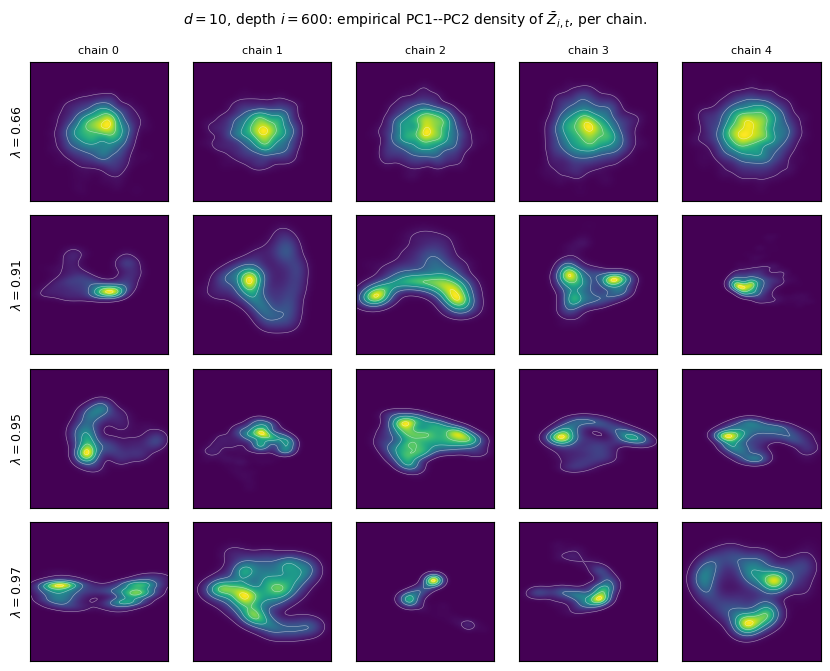

In [3]:
grid_density(snap10, LAMS_D10, d=10, depth=DEPTH_D10,
             out_path=FIGS / "pca_density_d10.pdf")

## Simulate $d = 100$ chains

Same parameters and seeds as `03_perchain_d100.ipynb`.

In [4]:
LAMS_D100 = (0.90, 0.99, 0.995)
DEPTH_D100 = 1000
SEEDS_D100 = {0.90: 1234, 0.99: 2024, 0.995: 2025}
snap100 = simulate_per_chain(d=100, n=N, lams=LAMS_D100, depth=DEPTH_D100,
                             n_chains=N_CHAINS, seeds=SEEDS_D100)
print("snap100 shape:", snap100.shape)

snap100 shape: (3, 5, 1000, 100)


## Figure 13 — `pca_density_d100.pdf`

wrote figs/pca_density_d100.pdf


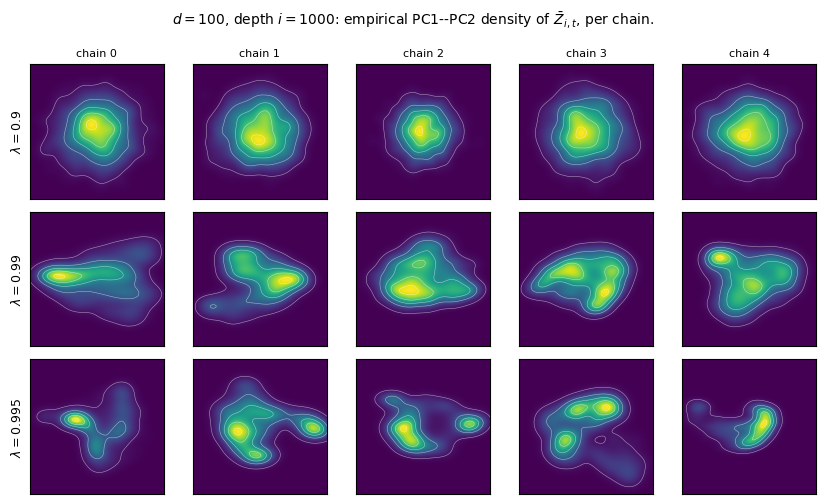

In [5]:
grid_density(snap100, LAMS_D100, d=100, depth=DEPTH_D100,
             out_path=FIGS / "pca_density_d100.pdf")